# 현실의 데이터 24: 설비 고장 예측 (예지보전)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/24_predictive_maintenance.ipynb)

**분야**: 제조 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 예지보전 · 설비 고장 예측 · 다운타임 줄이기

> 밀링 설비 가동 기록 1만 건, 고장은 3.4%. 온도 · 회전 속도 · 공구 마모로 고장을 미리 알 수 있을까?

**데이터**: AI4I 2020 Predictive Maintenance (약 0.5MB). UCI (Matzka, 2020). 실제 밀링 설비를 본떠 만든 합성 데이터 10,000건: 공기 · 공정 온도, 회전 속도, 토크, 공구 마모 시간, 고장 여부와 고장 종류 5가지.

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 가동 기록 한 건 |
| ② 입력 X | 제품 등급 · 온도 · 회전 속도 · 토크 · 공구 마모 |
| ③ 출력 y | 고장인가 (Machine failure) |
| ④ 평가지표 | 정밀도 · 재현율 |
| ⑤ 기준선 | 늘 '정상' |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Matzka (2020) Explainable Artificial Intelligence for Predictive Maintenance Applications, AI4I](https://doi.org/10.1109/AI4I49448.2020.00023)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

In [2]:
URL = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"
with zipfile.ZipFile(download(URL, "data/ai4i2020.zip")) as z:
    df = pd.read_csv(z.open("ai4i2020.csv"))
print(df.shape)
df.head()

(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 열어 보기

고장은 몇 %? 그리고 `TWF`, `HDF`, `PWF`, `OSF`, `RNF` 는 무엇일까? (공구 마모 · 열 방출 · 전력 · 과부하 · 무작위 고장, 즉 **고장의 종류**)

failure rate: 3.4%
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
Name: count, dtype: int64


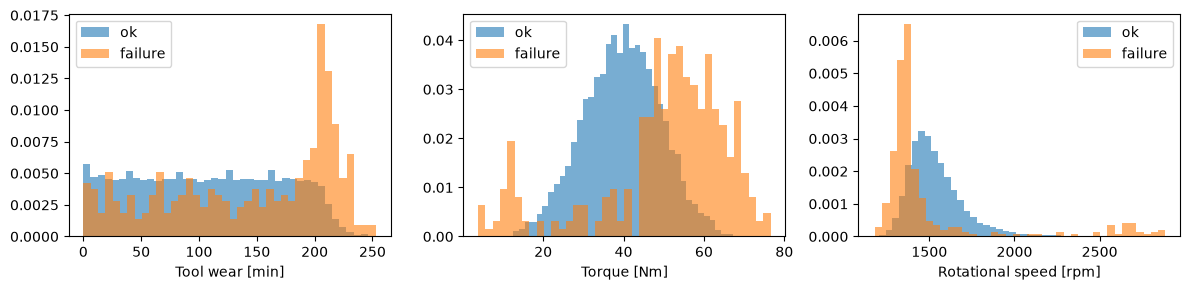

In [3]:
print(f"failure rate: {df['Machine failure'].mean():.1%}")
modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
print(df[modes].sum().rename("count"))
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
for ax, col in zip(axs, ["Tool wear [min]", "Torque [Nm]", "Rotational speed [rpm]"]):
    for f, name in [(0, "ok"), (1, "failure")]:
        ax.hist(df.loc[df["Machine failure"] == f, col], bins=40, density=True, alpha=0.6, label=name)
    ax.set_xlabel(col); ax.legend()
plt.tight_layout(); plt.show()

## 문제 하나 골라 보기: 가동 기록 → 고장일까

**함정**: 고장 종류 열 (`TWF` …) 은 고장이 **난 뒤에** 적히는 값이다. 입력에 넣으면 답을 보고 맞히는 셈이다. 넣을 때와 뺄 때를 비교한다.

In [4]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split

def precision_recall(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1)); fp = np.sum((y_pred == 1) & (y_true == 0)); fn = np.sum((y_pred == 0) & (y_true == 1))
    return (tp / (tp + fp) if tp + fp else 0.0), tp / (tp + fn)

sensors = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
X = pd.get_dummies(df[sensors + ["Type"] + modes], columns=["Type"], dtype=float)
y = df["Machine failure"].values
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)

p, r = precision_recall(yte, np.zeros(len(yte), dtype=int))
print(f"{'always ok':24s} accuracy {np.mean(yte == 0):.1%}  precision {p:.0%}  recall {r:.0%}")
for name, cols in [("sensors only", [c for c in X.columns if c not in modes]), ("+ failure-mode columns", list(X.columns))]:
    m = HistGradientBoostingClassifier(random_state=0).fit(Xtr[cols], ytr)
    pred = m.predict(Xte[cols]); p, r = precision_recall(yte, pred)
    print(f"{name:24s} accuracy {np.mean(yte == pred):.1%}  precision {p:.0%}  recall {r:.0%}")

always ok                accuracy 96.6%  precision 0%  recall 0%


sensors only             accuracy 98.4%  precision 86%  recall 63%


+ failure-mode columns   accuracy 99.8%  precision 99%  recall 95%


## 다른 문제로 바꿔 보기

- **예지보전의 진짜 질문**: '지금 고장인가' 가 아니라 '**앞으로 몇 시간 안에** 고장 날까' 다. 그러려면 한 행이 '설비 × 시각' 이고, 미래의 고장을 y 로 붙여야 한다. 이 데이터는 시간 순서가 없는 합성 데이터라 그걸 할 수 없다.
- **고장 종류 맞히기**: y 를 '고장 종류 5가지 중 무엇' 으로 바꾸면? 정비 팀이 무엇을 준비할지 정할 수 있다.
- 이 데이터는 **합성** 이다. 실제 공장 데이터 (예: 반도체 SECOM) 보다 훨씬 깔끔하고 잘 맞는다는 점도 기억하자.

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |